# Plotting

In [42]:
%load_ext autoreload
%autoreload 2
from lib.latex_plots import configure_matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

configure_matplotlib()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
DATA = Path("../data")
PROCESSED = DATA / "processed"
FIGS = Path("../plots/adri")

df = pd.read_parquet(PROCESSED / "apc_oa_works.parquet")

## Has Catalan science moved to open access?

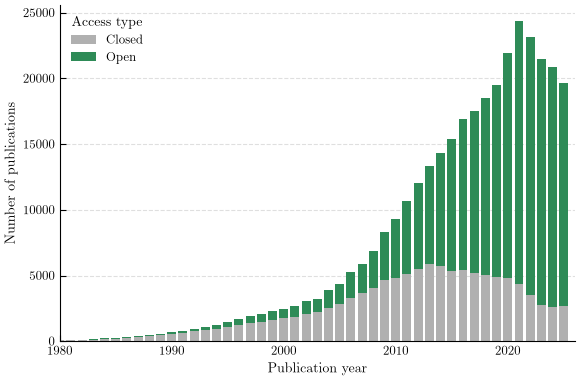

In [44]:
def plot_open_vs_closed_by_year(
    df: pd.DataFrame,
    *,
    min_year: int | None = None,
    max_year: int | None = None,
    as_percentage: bool = False,
    save_path: Path | None = None,
    figsize: tuple[float, float] = (10, 5.5),
):
    """
    Stacked bar chart: open access vs closed publications per year.

    Parameters
    ----------
    df : DataFrame with 'year' (int) and 'is_open_access' (bool).
    min_year, max_year : optional year bounds (inclusive).
    as_percentage : if True, normalise each year's stack to 100 %.
    save_path : optional Path to save the figure (PNG/PDF/SVG).
    """
    data = df.dropna(subset=["year", "is_open_access"]).copy()
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]

    # Count papers per year × OA status
    counts = (
        data.groupby(["year", "is_open_access"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    # Ensure both columns exist even if one status is missing
    for col in (False, True):
        if col not in counts.columns:
            counts[col] = 0
    # display(counts)
    
    if as_percentage:
        plot_data = counts.div(counts.sum(axis=1), axis=0) * 100
    else:
        plot_data = counts

    years = plot_data.index.astype(int)
    closed_vals = plot_data[False].values
    open_vals = plot_data[True].values

    fig, ax = plt.subplots(figsize=figsize)

    color_closed = "#B0B0B0"   # neutral grey
    color_open   = "#2E8B57"   # sea green

    ax.bar(years, closed_vals, label="Closed", color=color_closed, width=0.8)
    ax.bar(years, open_vals, bottom=closed_vals, label="Open",
           color=color_open, width=0.8)

    # --- Styling -------------------------------------------------------------
    ax.set_xlabel("Publication year")
    if as_percentage:
        ax.set_ylabel("Share of publications (%)")
        ax.set_ylim(0, 100)
    else:
        ax.set_ylabel("Number of publications")

    # ax.set_title("Open access vs. closed publications by year (Catalonia)",
    #              pad=12, fontsize=13, weight="semibold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    # ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=0)

    ax.legend(title="Access type", frameon=False, loc="upper left")

    if save_path is not None:
        fig.tight_layout()
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    fig.tight_layout()
    return fig, ax


fig, ax = plot_open_vs_closed_by_year(df, min_year=1980, max_year=2025, figsize=(6, 4))
ax.set_xlim(1980, 2026)
fig.savefig(FIGS / "open_vs_closed_by_year.pdf", bbox_inches="tight")
fig.savefig(FIGS / "open_vs_closed_by_year.png", bbox_inches="tight")
plt.show()

## Top publishers by year. Are we dependent on some publishers? 

                                                n_papers  share_pct  \
publisher_name                                                        
Elsevier BV                                        98133  28.679436   
Wiley                                              33000   9.644272   
Springer Science+Business Media                    26152   7.642940   
Multidisciplinary Digital Publishing Institute     16296   4.762517   
Oxford University Press                            11733   3.428977   
Other                                             156858  45.841857   

                                                n_open_access  pct_open_access  
publisher_name                                                                  
Elsevier BV                                             53231        54.243730  
Wiley                                                   18683        56.615152  
Springer Science+Business Media                         13743        52.550474  
Multidisciplinary Digital 

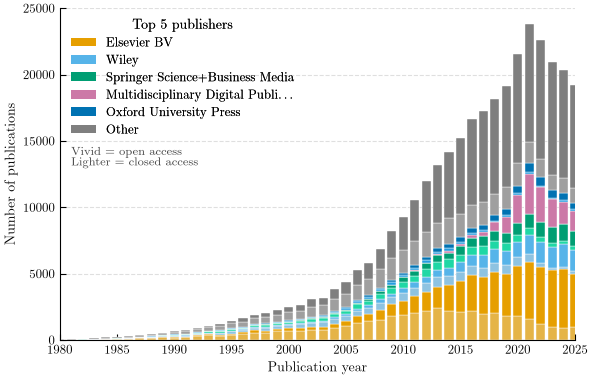

In [45]:
from pathlib import Path
import colorsys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch


def _truncate(label: str, n: int = 30) -> str:
    label = str(label)
    return label if len(label) <= n else label[: n - 1] + "…"


def _dim(color: str, amount: float = 0.45) -> tuple:
    """Desaturate + lighten a colour for the 'closed access' segments.

    Done in HLS space so bright colours like yellow (#F0E442) don't wash
    out into white when dimmed.
    """
    r, g, b = to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    new_l = l + (1 - l) * amount
    new_s = s * (1 - amount)
    return colorsys.hls_to_rgb(h, new_l, new_s)


def plot_top_publishers_by_year(
    df: pd.DataFrame,
    *,
    top_n: int = 5,
    include_other: bool = True,
    min_year: int | None = None,
    max_year: int | None = None,
    aggregation_column: str = "publisher_name",
    oa_column: str = "is_open_access",
    save_path: Path | None = None,
    figsize: tuple[float, float] = (8, 4.5),
):
    """
    Stacked bar chart per year of papers from the top-N publishers
    (by total count across the whole period), split into open vs closed
    access within each publisher:

        - vivid colour  = open access papers
        - dimmed colour = closed access papers

    Returns (fig, ax, summary).
    """
    data = df.dropna(subset=["year", aggregation_column, oa_column]).copy()
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]

    if data.empty:
        raise ValueError("No data left after filtering.")

    totals = data.groupby(aggregation_column).size().sort_values(ascending=False)
    top_pubs = totals.head(top_n).index.tolist()

    data["aggregated_group"] = data[aggregation_column].where(
        data[aggregation_column].isin(top_pubs), "Other"
    )

    years = np.sort(data["year"].unique().astype(int))

    def _pivot(mask: pd.Series) -> pd.DataFrame:
        return (
            data[mask]
            .groupby(["year", "aggregated_group"]).size()
            .unstack(fill_value=0)
            .reindex(index=years, fill_value=0)
        )

    pivot_open = _pivot(data[oa_column])
    pivot_closed = _pivot(~data[oa_column])

    all_cols = set(pivot_open.columns) | set(pivot_closed.columns)
    order = [p for p in top_pubs if p in all_cols]
    if include_other and "Other" in all_cols:
        order.append("Other")

    # Okabe-Ito colourblind-safe palette (matches the user's)'#D55E00', '#CC79A7'
    base_colors = ['#E69F00', '#56B4E9', '#009E73', '#CC79A7', '#0072B2']
    if include_other:
        base_colors = base_colors + ["#7F7F7F"]

    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(len(years), dtype=float)

    pub_handles = []
    for i, pub in enumerate(order):
        closed_vals = (
            pivot_closed[pub].to_numpy(dtype=float)
            if pub in pivot_closed.columns else np.zeros(len(years))
        )
        open_vals = (
            pivot_open[pub].to_numpy(dtype=float)
            if pub in pivot_open.columns else np.zeros(len(years))
        )

        vivid = base_colors[i] if i < len(base_colors) else "#888888"
        dimmed = _dim(vivid, 0.25)

        # closed (dim) at the bottom, open (vivid) on top
        ax.bar(years, closed_vals, bottom=bottom, width=0.8,
               color=dimmed, edgecolor="white", linewidth=0.3)
        bottom += closed_vals
        ax.bar(years, open_vals, bottom=bottom, width=0.8,
               color=vivid, edgecolor="white", linewidth=0.3)
        bottom += open_vals

        pub_handles.append(Patch(facecolor=vivid, label=_truncate(pub, 32)))

    # --- Styling -------------------------------------------------------------
    ax.set_xlabel("Publication year")
    ax.set_ylabel("Number of publications")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)

    # Publisher legend (upper-left)
    leg_pub = ax.legend(
        handles=pub_handles,
        title=f"Top {top_n} publishers",
        loc="upper left", frameon=False,
    )
    ax.add_artist(leg_pub)

    # Access-type hint as small text (keeps the plot clean, no 2nd legend)
    ax.annotate(
        xy=(1981, 13000),
        text="Vivid = open access\nLighter = closed access",
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=8.5, style="italic", color="#444",
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    # --- Summary table -------------------------------------------------------
    total_papers = int(totals.sum())
    summary = totals.head(top_n).to_frame(name="n_papers")
    summary["share_pct"] = 100 * summary["n_papers"] / total_papers

    oa_counts = data[data[oa_column]].groupby(aggregation_column).size()
    summary["n_open_access"] = summary.index.map(oa_counts).fillna(0).astype(int)
    summary["pct_open_access"] = 100 * summary["n_open_access"] / summary["n_papers"]

    if include_other:
        rest = totals.iloc[top_n:]
        if not rest.empty:
            other_total = int(rest.sum())
            other_oa = int(data.loc[
                (~data[aggregation_column].isin(top_pubs)) & (data[oa_column])
            ].shape[0])
            summary.loc["Other"] = [
                other_total,
                100 * other_total / total_papers,
                other_oa,
                100 * other_oa / other_total,
            ]

    return fig, ax, summary


# --- Usage (same signature as before) ---------------------------------------
fig, ax, summary = plot_top_publishers_by_year(
    df, top_n=5, min_year=1980, figsize=(6, 4),
    aggregation_column="publisher_name",
)
ax.set_xlim(1980, 2025)
fig.savefig(FIGS / "top5_publishers_by_year.pdf", bbox_inches="tight")
fig.savefig(FIGS / "top5_publishers_by_year.png", bbox_inches="tight")
print(summary)
plt.show()

## Price comparision of top 5 papers on each science domain per year (should see that the covid year price is lower for health science?)

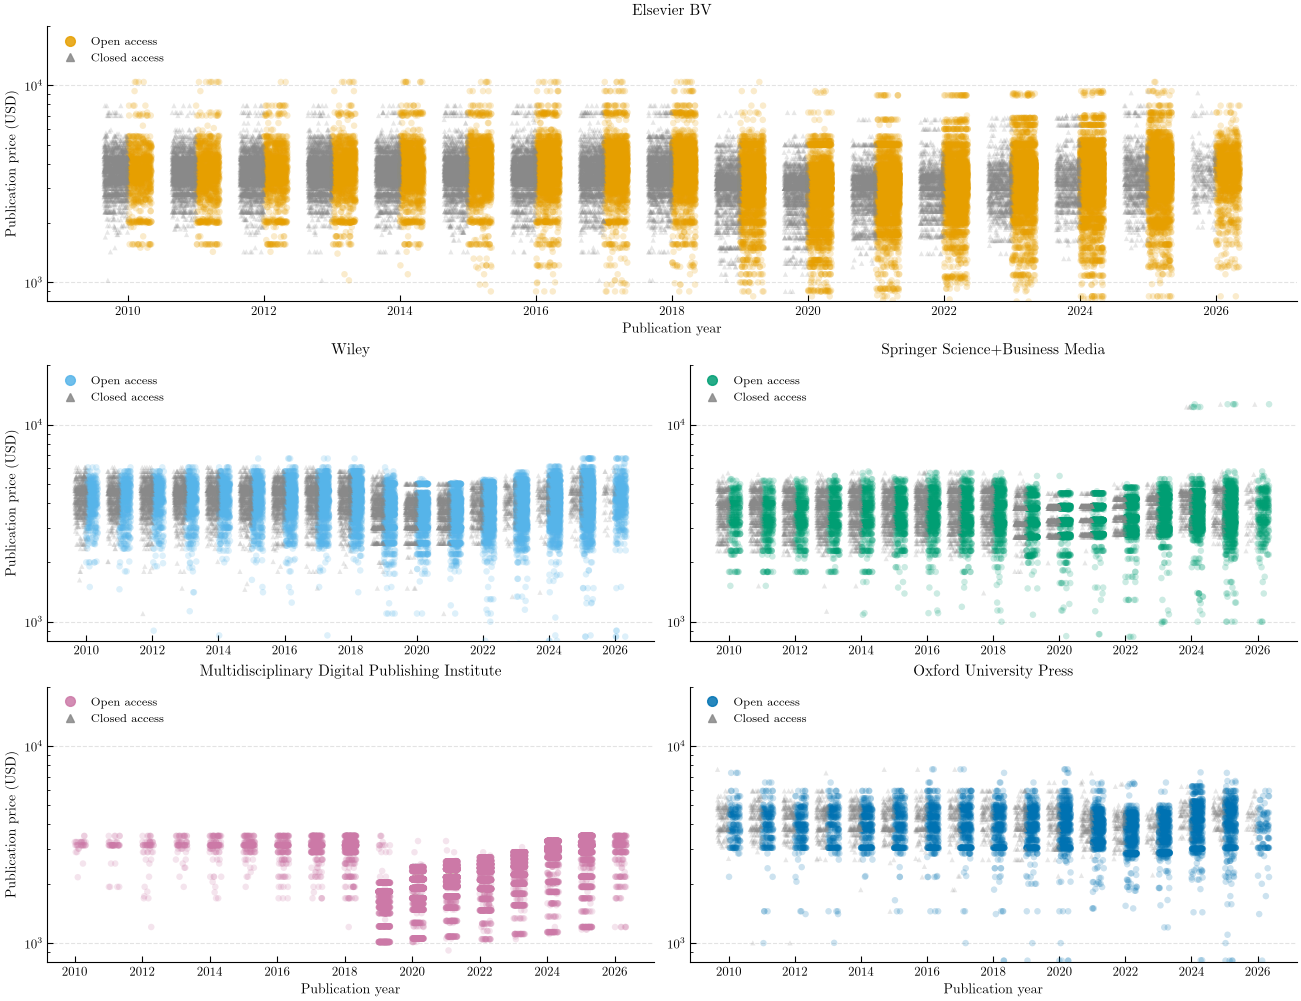

In [ ]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#CC79A7', '#0072B2']


def _truncate(label: str, n: int = 28) -> str:
    label = str(label)
    return label if len(label) <= n else label[: n - 1] + "…"


def plot_prices_panel(
    df: pd.DataFrame,
    publishers: list[str],
    *,
    value_col: str = "apc_list_value_usd",
    label_col: str = "Publication price ($)",
    oa_column: str = "is_open_access",
    min_year: int | None = None,
    max_year: int | None = None,
    drop_zero: bool = True,
    log_y: bool = True,
    jitter: float = 0.30,
    seed: int = 42,
    show_medians: bool = False,
    min_n_median: int = 5,
    shared_y: bool = True,
    save_path: Path | None = None,
    figsize: tuple = (13, 10),
):
    """
    3x2 panel of APC scatter plots per publisher:

        Row 0        : publishers[0]  (spans both columns)
        Row 1, cols 0/1 : publishers[1], publishers[2]
        Row 2, cols 0/1 : publishers[3], publishers[4]

    Y-axis is shared across the five panels (shared_y=True) so publishers
    are visually comparable. Only the left column and top row show the
    Y tick labels + Y axis label, keeping the figure clean.

    Returns (fig, axes).
    """
    # --- Data prep -----------------------------------------------------------
    data = df.dropna(
        subset=["year", value_col, oa_column, "publisher_name"]
    ).copy()
    data = data[data["publisher_name"].isin(publishers)]
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]
    if drop_zero:
        data = data[data[value_col] > 0]
    if data.empty:
        raise ValueError("No data left after filtering.")

    rng = np.random.default_rng(seed)
    data["_x"] = data["year"].astype(float) + rng.uniform(
        0, jitter, len(data)
    )*(data[oa_column].map({True: 1, False: -1}))

    # --- Shared y-limits ----------------------------------------------------
    ylims = None
    if shared_y:
        vmin = float(data[value_col].min())
        vmax = float(data[value_col].max())
        pad = 0.05
        if log_y and vmin > 0:
            ylims = (vmin * 10 ** (-pad), vmax * 10 ** (pad))
        else:
            span = vmax - vmin if vmax > vmin else 1.0
            ylims = (vmin - pad * span, vmax + pad * span)

    color_of = {p: OKABE_ITO[i % len(OKABE_ITO)]
                for i, p in enumerate(publishers)}

    # --- Figure + GridSpec 3x2 ----------------------------------------------
    fig = plt.figure(figsize=figsize, constrained_layout=True)
    gs = fig.add_gridspec(3, 2)
    slots = [gs[0, :], gs[1, 0], gs[1, 1], gs[2, 0], gs[2, 1]]

    axes = []
    first_ax = None
    for i, pub in enumerate(publishers[:5]):
        ax = fig.add_subplot(slots[i], sharey=first_ax)
        if first_ax is None:
            first_ax = ax
        axes.append(ax)

        sub = data[data["publisher_name"] == pub]
        color = color_of[pub]
        closed_color = "#898989"

        if sub.empty:
            ax.text(0.5, 0.5, "No data after filters",
                    transform=ax.transAxes, ha="center", va="center",
                    fontsize=10, color="#888")
        else:
            open_ = sub[sub[oa_column]]
            closed = sub[~sub[oa_column]]
            if not closed.empty:
                ax.scatter(
                    closed["_x"], closed[value_col],
                    s=14, marker="^", color=closed_color, alpha=0.2,
                    edgecolors="none", rasterized=True, zorder=4,
                )
            if not open_.empty:
                ax.scatter(
                    open_["_x"], open_[value_col],
                    s=22, marker="o", color=color, alpha=0.2,
                    edgecolors="none", rasterized=True, zorder=3,
                )

            if show_medians:
                med = (
                    sub.groupby(["year", oa_column])[value_col]
                       .agg(["median", "count"]).reset_index()
                )
                med = med[med["count"] >= min_n_median]
                for is_oa, c, ls, lw in [
                    (False, closed_color, "--", 1.6),
                    (True,  color,        "-",  2.0),
                ]:
                    m = med[med[oa_column] == is_oa]
                    if not m.empty:
                        ax.plot(m["year"], m["median"], color=c,
                                linestyle=ls, linewidth=lw, zorder=4)

        # --- Styling ---------------------------------------------------------
        if log_y:
            ax.set_yscale("log")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(True, which="major", axis="y", linestyle="--", alpha=0.35)
        ax.set_axisbelow(True)
        ax.set_title(pub, pad=8,
                     fontsize=11, weight="semibold")

        handles = [
            Line2D([0], [0], marker="o", linestyle="", markersize=7,
                   color=color, alpha=0.85, label="Open access"),
            Line2D([0], [0], marker="^", linestyle="", markersize=6,
                   color=closed_color, alpha=0.85, label="Closed access"),
        ]
        if show_medians:
            handles.append(
                Line2D([0], [0], color="#666", linestyle="-", linewidth=1.6,
                       label="Median per year")
            )
        ax.legend(handles=handles, loc="upper left",
                  frameon=False, fontsize=8.5)

    # --- Apply shared y-limit (propagates to all via sharey) ----------------
    if ylims is not None and first_ax is not None:
        first_ax.set_ylim(*ylims)

    # --- Axis labels: left column + top row keep Y labels, bottom row X ----
    # Panel index mapping: 0=top, 1=row1-left, 2=row1-right, 3=row2-left, 4=row2-right
    y_label_panels = {0, 1, 3}
    x_label_panels = {0, 3, 4}
    for i, ax in enumerate(axes):
        if i in y_label_panels:
            ax.tick_params(labelleft=True)
            ax.set_ylabel(f"{label_col}")
        else:
            ax.set_ylabel("")
        ax.set_xlabel("Publication year" if i in x_label_panels else "")

    # --- Save ----------------------------------------------------------------
    if save_path is not None:
        save_path = Path(save_path)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        if save_path.suffix.lower() != ".pdf":
            fig.savefig(save_path.with_suffix(".pdf"), bbox_inches="tight")

    return fig, axes


# --- Usage -------------------------------------------------------------------
TOP5 = [
    "Elsevier BV",
    "Wiley",
    "Springer Science+Business Media",
    "Multidisciplinary Digital Publishing Institute",
    "Oxford University Press",
]

fig, axes = plot_prices_panel(
    df, TOP5,
    value_col="apc_list_value_usd",
    label_col=r'Publication price (USD)',
    min_year=2010,
    jitter=0.35,
    show_medians=False, shared_y=True,
    # save_path=FIGS / "prices_panel_top5_publishers.png",
)
import matplotlib.ticker as ticker
for ax in axes:
    ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
    ax.set_ylim(8e2, 2e4)

fig.savefig(FIGS / "prices_panel_top5_publishers.png", bbox_inches="tight")
fig.savefig(FIGS / "prices_panel_top5_publishers.pdf", bbox_inches="tight")

plt.show()

## How many money is spent on each domain to publication fees for the top 5 publishers?

In [56]:
TOP5 = [
    "Elsevier BV",
    "Wiley",
    "Springer Science+Business Media",
    "Multidisciplinary Digital Publishing Institute",
    "Oxford University Press",
]
aggregation = df.copy()
# 1) Create the grouping column
aggregation['publisher_group'] = aggregation['publisher_name'].where(
    aggregation['publisher_name'].isin(TOP5), 'Other'
)

# 2) Aggregate by sum (keeping domain_name)
aggregated = (
    aggregation.groupby(['domain_name', 'publisher_group', 'year'], as_index=False)['apc_list_value_usd']
      .sum()
      .rename(columns={'apc_list_value_usd': 'apc_total_usd', 'domain_name': 'Domain', 'publisher_group': 'Publisher'})
      .sort_values(['year'])
)

aggregated.to_csv(PROCESSED / "apc_total_by_domain_and_publisher_sankey.csv", index=False)

In [71]:
import pandas as pd
import lib.alluvial as alluvial  # Make sure alluvial.py is in your working directory
import matplotlib.pyplot as plt
from tqdm import tqdm

def wrap_text(text, width=15):
    """
    Wrap text into lines of at most `width` characters.
    
    - Breaks on whitespace where possible.
    - Hard-breaks any single word longer than `width`.
    - Collapses existing runs of whitespace (spaces, tabs, newlines) to single spaces.
    
    Returns a single string with '\n' between lines.
    """
    if text is None:
        return ""
    text = str(text)

    # Split on any whitespace; this also handles pre-existing newlines/tabs.
    words = text.split()
    if not words:
        return ""

    lines = []
    current = ""

    for word in words:
        # Hard-break words that are longer than the allowed width.
        while len(word) > width:
            if current:
                lines.append(current)
                current = ""
            lines.append(word[:width])
            word = word[width:]
        if not word:
            continue

        if not current:
            current = word
        elif len(current) + 1 + len(word) <= width:
            current += " " + word          # fits: append with a space
        else:
            lines.append(current)          # doesn't fit: start a new line
            current = word

    if current:
        lines.append(current)

    return "\n".join(lines)

colors = ['#E69F00', "#7F7F7F", '#56B4E9', '#009E73', '#CC79A7', '#0072B2']

# Load your CSV
csv = pd.read_csv(PROCESSED / "apc_total_by_domain_and_publisher_sankey.csv")   # or use the simulated df from above
csv = csv[csv['year'] > 2005]  # Filter out years before 1980
ALLUVIALS = FIGS/"alluvial"
ALLUVIALS.mkdir(exist_ok=True, parents=True)
# display(df)
# Build a nested dictionary: {source_category: {target_category: total_volume, ...}, ...}
for i, year in tqdm(list(enumerate(sorted(csv['year'].unique())))):
    input_data = {}
    csv_year = csv[csv['year'] == year]
    for _, row in csv_year.iterrows():
        src = row['Domain']
        tgt = wrap_text(row['Publisher'], 17)
        vol = row["apc_total_usd"]
        if src not in input_data:
            input_data[src] = {}
        # If multiple rows have the same (src, tgt), sum their volumes
        input_data[src][tgt] = input_data[src].get(tgt, 0) + vol


    # Plot using the standalone script
    ax = alluvial.plot(input_data, color_side=1, colors=colors[::-1], alpha=0.8)
    ax.set_title("Spent money in publication fees by domain and publisher in " + str(year))
    ax.figure.savefig(ALLUVIALS/f"{i}_alluvial.png", dpi=200)
    plt.close()
    # plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:03<00:00,  6.51it/s]


In [ ]:
# only execute if ffmpeg is present in your system, otherwise comment out the following line!!!!!
! ffmpeg -y -f image2 -framerate 2 -i {ALLUVIALS/"%d_alluvial.png"} -vf "scale=1200:-1:flags=lanczos,split[s0][s1];[s0]palettegen=max_colors=256[p];[s1][p]paletteuse=dither=sierra2_4a" -loop 0 {FIGS/"alluvial.gif"}

ffmpeg version 8.1.3 Copyright (c) 2000-2026 the FFmpeg developers
  built with gcc 16 (GCC)
  configuration: --prefix=/usr --bindir=/usr/bin --datadir=/usr/share/ffmpeg --docdir=/usr/share/doc/ffmpeg --incdir=/usr/include/ffmpeg --libdir=/usr/lib64 --mandir=/usr/share/man --arch=aarch64 --optflags='-O2 -flto=auto -ffat-lto-objects -fexceptions -g -grecord-gcc-switches -pipe -Wall -Werror=format-security -Wno-error=incompatible-pointer-types -Wp,-U_FORTIFY_SOURCE,-D_FORTIFY_SOURCE=3 -Wp,-D_GLIBCXX_ASSERTIONS -specs=/usr/lib/rpm/redhat/redhat-hardened-cc1 -fstack-protector-strong -specs=/usr/lib/rpm/redhat/redhat-annobin-cc1 -mbranch-protection=standard -fasynchronous-unwind-tables -fstack-clash-protection -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer ' --extra-cflags=-I/usr/include/decklink --extra-cxxflags=-I/usr/include/decklink --extra-ldflags='-Wl,-z,relro -Wl,--as-needed -Wl,-z,pack-relative-relocs -Wl,-z,now -specs=/usr/lib/rpm/redhat/redhat-hardened-ld -specs=/usr/lib/rpm